# Selección de variables

Complementa la Fase 3. El ranking de información mutua se calcula **solo con el conjunto de entrenamiento**. La Iteración 2 realiza además selección avanzada sobre las columnas codificadas mediante `SelectPercentile`, dentro de cada fold de `GridSearchCV`, evitando ajustar el selector con validación o test.

In [1]:
from pathlib import Path
import sys
import warnings
import joblib
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "bank-full.csv").is_file() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.etl import POST_CONTACT_FEATURES, load_bank_data, split_data
from src.modeling import rank_features

df = load_bank_data()
splits = split_data(df, random_state=42)
print("Variables excluidas por no estar disponibles antes del contacto:", list(POST_CONTACT_FEATURES))
print("Predictores candidatos:", splits.x_train.columns.tolist())

Variables excluidas por no estar disponibles antes del contacto: ['duration', 'campaign', 'day', 'month', 'contact']
Predictores candidatos: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'pdays', 'previous', 'poutcome']


## 1. Ranking por información mutua (solo entrenamiento)

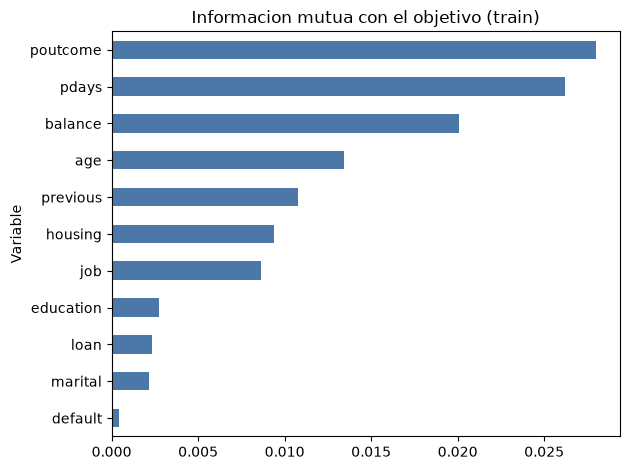

,Variable,Importancia
0,poutcome,0.0280
1,pdays,0.0262
2,balance,0.0201
3,age,0.0134
4,previous,0.0108
5,housing,0.0094
6,job,0.0087
7,education,0.0027
8,loan,0.0023
9,marital,0.0021


In [2]:
ranking = rank_features(splits.x_train, splits.y_train)
ranking.sort_values("Importancia").plot(x="Variable", y="Importancia", kind="barh", legend=False,
                                        color="#4C78A8", title="Informacion mutua con el objetivo (train)")
plt.tight_layout(); plt.show()
ranking.round(4)

## 2. Selección avanzada de la Iteración 2 (`SelectPercentile`)
Se muestran las columnas codificadas que conserva el selector del Random Forest de la Iteración 2 ya entrenado.

In [3]:
modelo = joblib.load(ROOT / "Modelos" / "iteracion_2_random_forest.joblib")
nombres = modelo.named_steps["preprocessing"].get_feature_names_out()
mascara = modelo.named_steps["selection"].get_support()
scores = modelo.named_steps["selection"].scores_
tabla = pd.DataFrame({"Columna codificada": nombres, "Score F": scores, "Seleccionada": mascara})
print(f"Columnas codificadas: {len(nombres)} | conservadas: {int(mascara.sum())} "
      f"({modelo.named_steps['selection'].percentile}%)")
tabla.sort_values("Score F", ascending=False).head(15).round(2)

Columnas codificadas: 33 | conservadas: 24 (75%)


,Columna codificada,Score F,Seleccionada
31,categorical__poutcome_success,2668.52,True
32,categorical__poutcome_unknown,727.53,True
26,categorical__housing_yes,520.72,True
25,categorical__housing_no,520.72,True
3,numeric__previous,299.61,True
2,numeric__pdays,276.30,True
9,categorical__job_retired,170.60,True
12,categorical__job_student,163.97,True
5,categorical__job_blue-collar,154.32,True
21,categorical__education_tertiary,126.12,True


## 3. Conclusión
- Las variables con mayor información mutua orientan qué predictores priorizar; la app Streamlit permite elegir el subconjunto de predictores.
- El filtro `SelectPercentile` reduce la dimensionalidad tras el One-Hot Encoding y se ajusta únicamente con datos de entrenamiento en cada fold.
- `duration`, `campaign`, `day`, `month` y `contact` se excluyen para evitar fuga de información.